# 02 — Data Cleaning, Solid Mask Generation, Splitting & Preprocessing

- Duplicate auditing & removal, hollow-to-solid binary mask generation (with border-clipped ellipse repair), and leakage-free exam-grouped HC-stratified **70% / 15% / 15%** splitting.
- Dimension standardization (+ `mm/px` recalibration), intensity normalization, and edge-preserving speckle-reduction filtering.

In [6]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().resolve().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import pandas as pd
from IPython.display import Image, display

from src.config import (
    RAW_TRAIN_DIR,
    RAW_TRAIN_CSV,
    INTERIM_DATA_DIR,
    PROCESSED_DATA_DIR,
    SPLITS_DIR,
    FIGURES_DIR,
    COL_FILENAME,
    COL_PIXEL_SIZE,
    COL_HC_MM,
    RANDOM_SEED,
    DEFAULT_TARGET_SIZE,
)
from src.data_prep.cleaning import clean_hc18_metadata
from src.data_prep.masks import generate_solid_masks
from src.data_prep.splitting import create_grouped_stratified_splits
from src.data_prep.run_data_prep import plot_mask_verification, plot_split_distributions

print("Raw train dir:", RAW_TRAIN_DIR)
print("Raw train CSV:", RAW_TRAIN_CSV)

Raw train dir: C:\Users\DELL\Desktop\university\Fall 2026\Pattern Recognition\Project\Obstetric-Ultrasound-Segmentation-and-Measurement\data\raw\training_set
Raw train CSV: C:\Users\DELL\Desktop\university\Fall 2026\Pattern Recognition\Project\Obstetric-Ultrasound-Segmentation-and-Measurement\data\raw\training_set_pixel_size_and_HC.csv


## 1. Duplicate Audit & Resolution 
Audits both raw-file SHA-256 and decoded pixel-array SHA-256 across all 999 ultrasound images and annotations, reconstructs multi-plane `exam_group_id` clusters, drops redundant duplicates, and exports `data/interim/duplicate_audit.csv` and `data/interim/cleaned_metadata.csv`.

In [2]:
cleaned_df, duplicate_audit_df = clean_hc18_metadata()
print(f"Cleaned samples: {len(cleaned_df)} (from 999) across {cleaned_df['exam_group_id'].nunique()} unique exam groups.")
display(duplicate_audit_df)

Cleaned samples: 994 (from 999) across 779 unique exam groups.


,duplicate_group,match_type,action,filename,annotation_filename,seq_id,exam_group_id,pixel size,head circumference (mm),us_mad_vs_kept,ann_file_sha256_short,ann_pixel_sha256_short
0,1,exact_pixel_annotation,drop,306_2HC.png,306_2HC_Annotation.png,306,238,0.175531,165.68,0.0439,8987c9480828,d2d63ed3d0a2
1,1,exact_pixel_annotation,keep,308_HC.png,308_HC_Annotation.png,308,238,0.175531,165.68,0.0000,50fd5f9667eb,d2d63ed3d0a2
2,2,exact_file_annotation,drop,482_2HC.png,482_2HC_Annotation.png,482,382,0.145447,174.99,0.7133,a43a3097c075,dedecbc19266
3,2,exact_file_annotation,drop,483_3HC.png,483_3HC_Annotation.png,483,382,0.145447,174.99,0.7133,a43a3097c075,dedecbc19266
4,2,exact_file_annotation,keep,484_HC.png,484_HC_Annotation.png,484,382,0.145447,174.99,0.0000,a43a3097c075,dedecbc19266
5,3,exact_file_annotation,drop,629_2HC.png,629_2HC_Annotation.png,629,496,0.130545,166.73,0.1692,0559bddf9a44,d10874c5108e
6,3,exact_file_annotation,keep,630_HC.png,630_HC_Annotation.png,630,496,0.130545,166.73,0.0000,0559bddf9a44,d10874c5108e
7,4,exact_file_annotation,keep,978_3HC.png,978_3HC_Annotation.png,978,763,0.261567,312.49,0.0000,77c37915e3ae,074cff9f1b7f
8,4,exact_file_annotation,drop,979_4HC.png,979_4HC_Annotation.png,979,763,0.261567,312.49,0.0935,77c37915e3ae,074cff9f1b7f


## 2. Hollow Ellipse Contour to Solid Binary Mask Conversion 
Flood-fills all 994 cleaned `*_Annotation.png` contours into solid binary masks (`0` = background, `255` = head). Automatically detects the 4 border-clipped annotations (`231_HC`, `427_2HC`, `776_HC`, `977_HC`) whose ellipses touch the image boundary and repairs them via exact ellipse fitting (`cv2.fitEllipse`).

Mask fill methods: {'flood_fill': 990, 'ellipse_fit_border_repair': 4}
Foreground pixel share: 30.41% | Background: 69.59% | Ratio bg/fg: 2.289


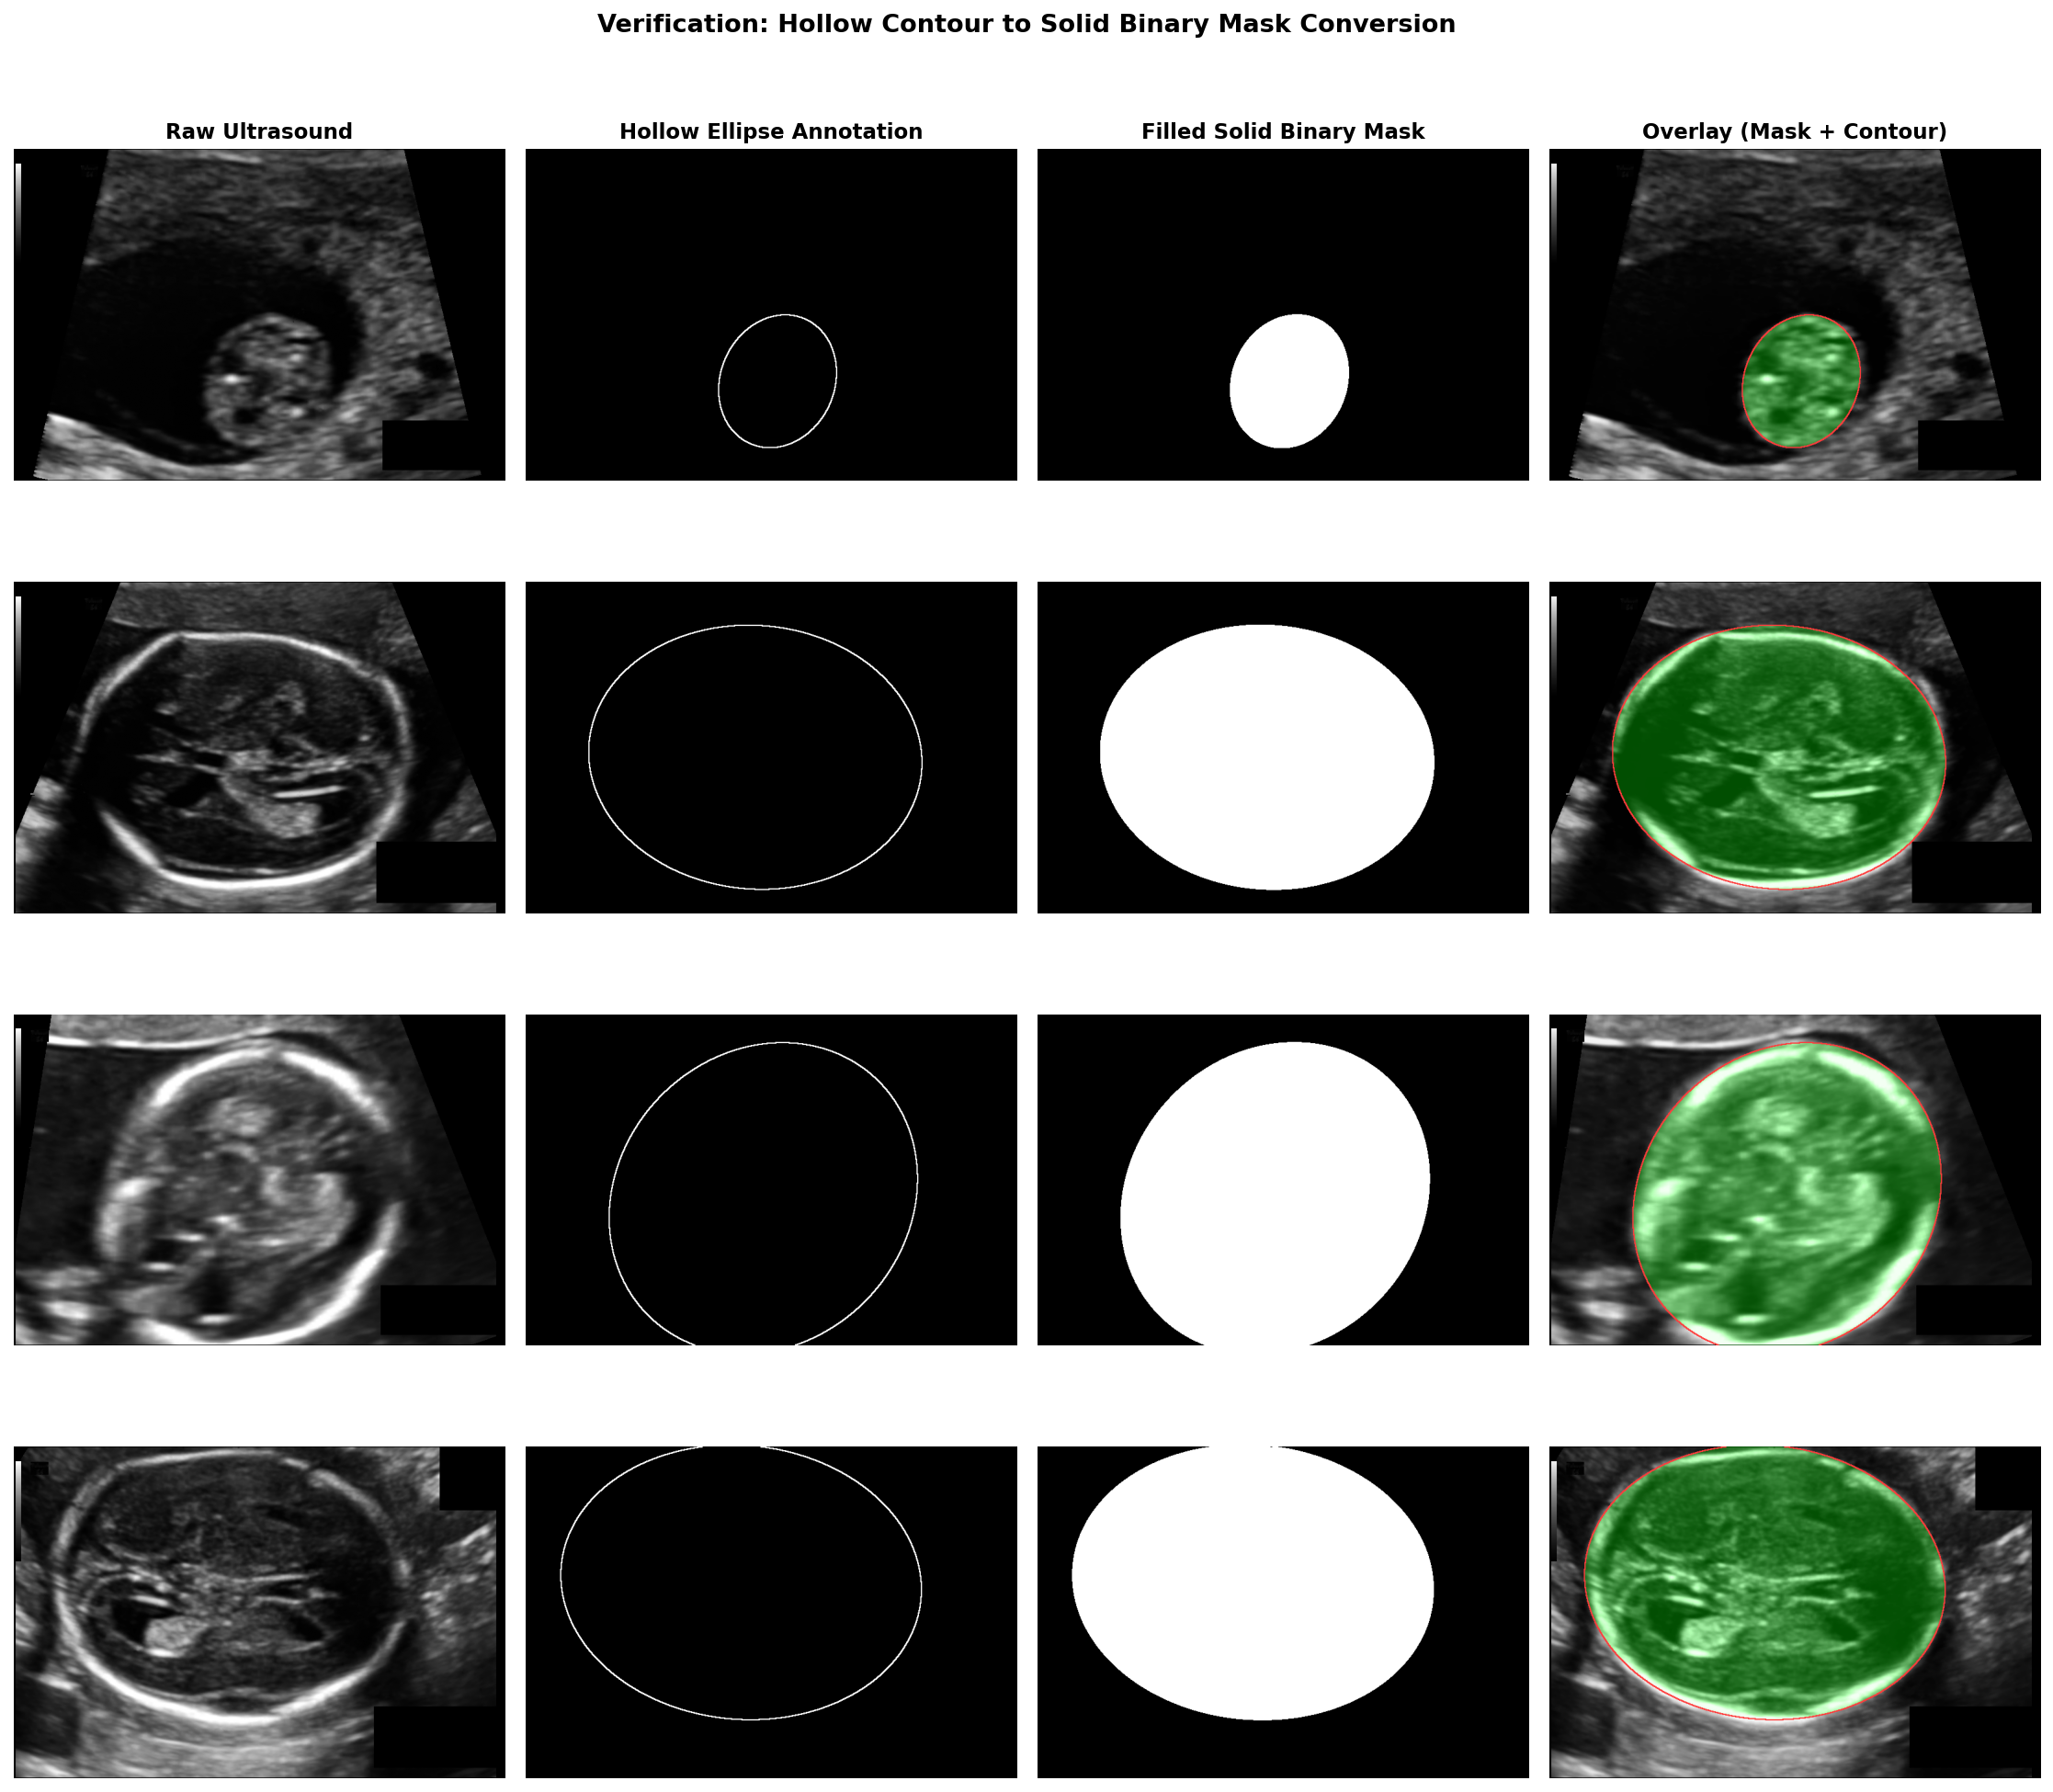

In [3]:
cleaned_df = generate_solid_masks(cleaned_df)
print("Mask fill methods:", cleaned_df["mask_fill_method"].value_counts().to_dict())
mean_fg = cleaned_df["fg_ratio"].mean()
print(f"Foreground pixel share: {mean_fg*100:.2f}% | Background: {(1-mean_fg)*100:.2f}% | Ratio bg/fg: {(1-mean_fg)/mean_fg:.3f}")

mask_fig_path = plot_mask_verification(cleaned_df)
display(Image(filename=str(mask_fig_path)))

## 3. Leakage-Free Exam-Grouped & HC-Stratified Split 
Splits the 994 cleaned images strictly by `exam_group_id` (779 exams) into **Train (70%) / Validation (15%) / Internal Test (15%)**, stratified across HC size strata (`<100`, `100-150`, `150-200`, `200-250`, `250-300`, `>300` mm), with automated assertions guaranteeing zero overlap in exams, filenames, and pixel hashes.

,split,n_images,image_share_pct,n_exams,hc_mean_mm,hc_median_mm,hc_std_mm,pixel_size_mean_mm,fg_pixel_pct,recommended_bce_pos_weight,bin_<100,bin_100-150,bin_150-200,bin_200-250,bin_250-300,bin_>300
0,train,693,69.72,545,173.93,174.10,64.89,0.13911,30.59,2.269,130,44,369,48,72,30
1,val,148,14.89,117,173.40,173.09,61.46,0.13813,30.52,2.277,24,9,87,9,13,6
2,test,153,15.39,117,176.59,173.96,70.90,0.14379,29.44,2.396,30,8,78,10,15,12


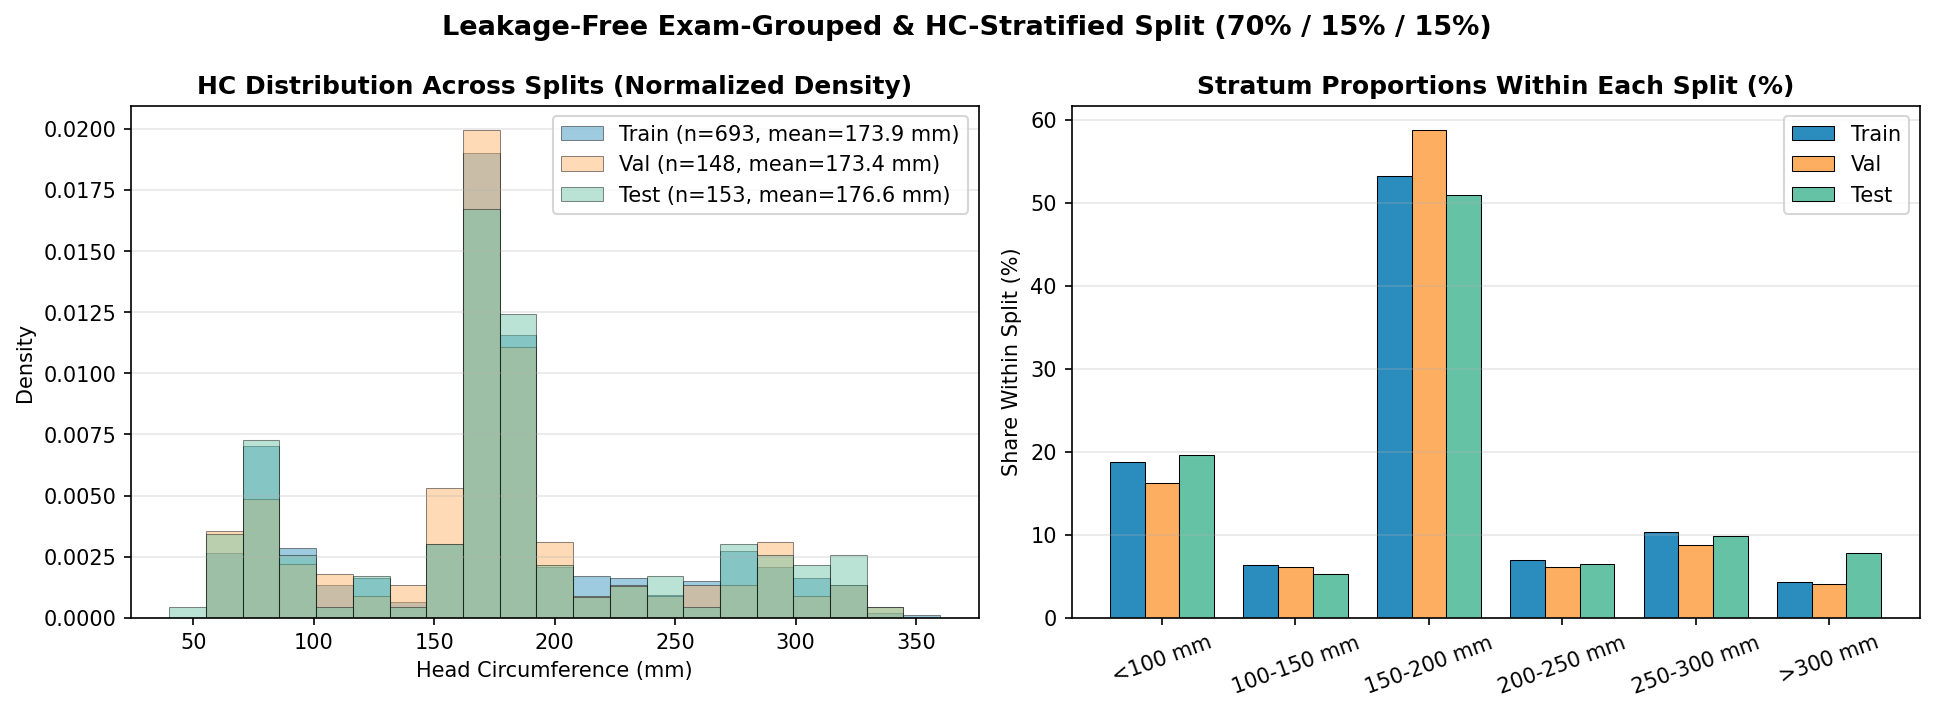

In [4]:
splits, split_summary_df = create_grouped_stratified_splits(cleaned_df)
display(split_summary_df)

split_fig_path = plot_split_distributions(splits)
display(Image(filename=str(split_fig_path)))

## 4. Resizing, Pixel-Size Recalibration, Normalization & Edge-Preserving Despeckling
- Standardizes all 994 images (`cv2.INTER_AREA`) and binary masks (`cv2.INTER_NEAREST`) to `256 × 384`, recalibrating exact anisotropic `pixel_size_x_mm` and `pixel_size_y_mm`.
- Applies robust per-image intensity normalization (`[0.5, 99.5]` percentile min-max over active ultrasound pixels, preserving black sector borders).
- Generates **both** `data/processed/images_raw_norm/` (control arm) and `data/processed/images_despeckled/` (experimental arm using Perona-Malik Anisotropic Diffusion), and benchmarks Bilateral, Anisotropic Diffusion, and Non-Local Means on the validation split (`n=148`).

Processed 994 image/mask pairs -> C:\Users\DELL\Desktop\university\Fall 2026\Pattern Recognition\Project\Obstetric-Ultrasound-Segmentation-and-Measurement\data\processed
HC calibration check after resizing: MAE = 0.285 mm | Median |Err| = 0.261 mm | 95th pct = 0.515 mm

Validation-set edge-preserving filter benchmark (n=148):


,filter,enl_mean,cnr_mean,epi_mean,interior_var_reduction_pct,runtime_ms_per_img
0,raw_normalized,1.897,0.5679,1.0000,0.00,0.00
1,bilateral,2.054,0.5667,0.8302,7.08,10.66
2,anisotropic_diffusion,2.085,0.5645,0.6699,7.49,66.14
3,nlm,1.982,0.5722,0.9168,5.01,450.42


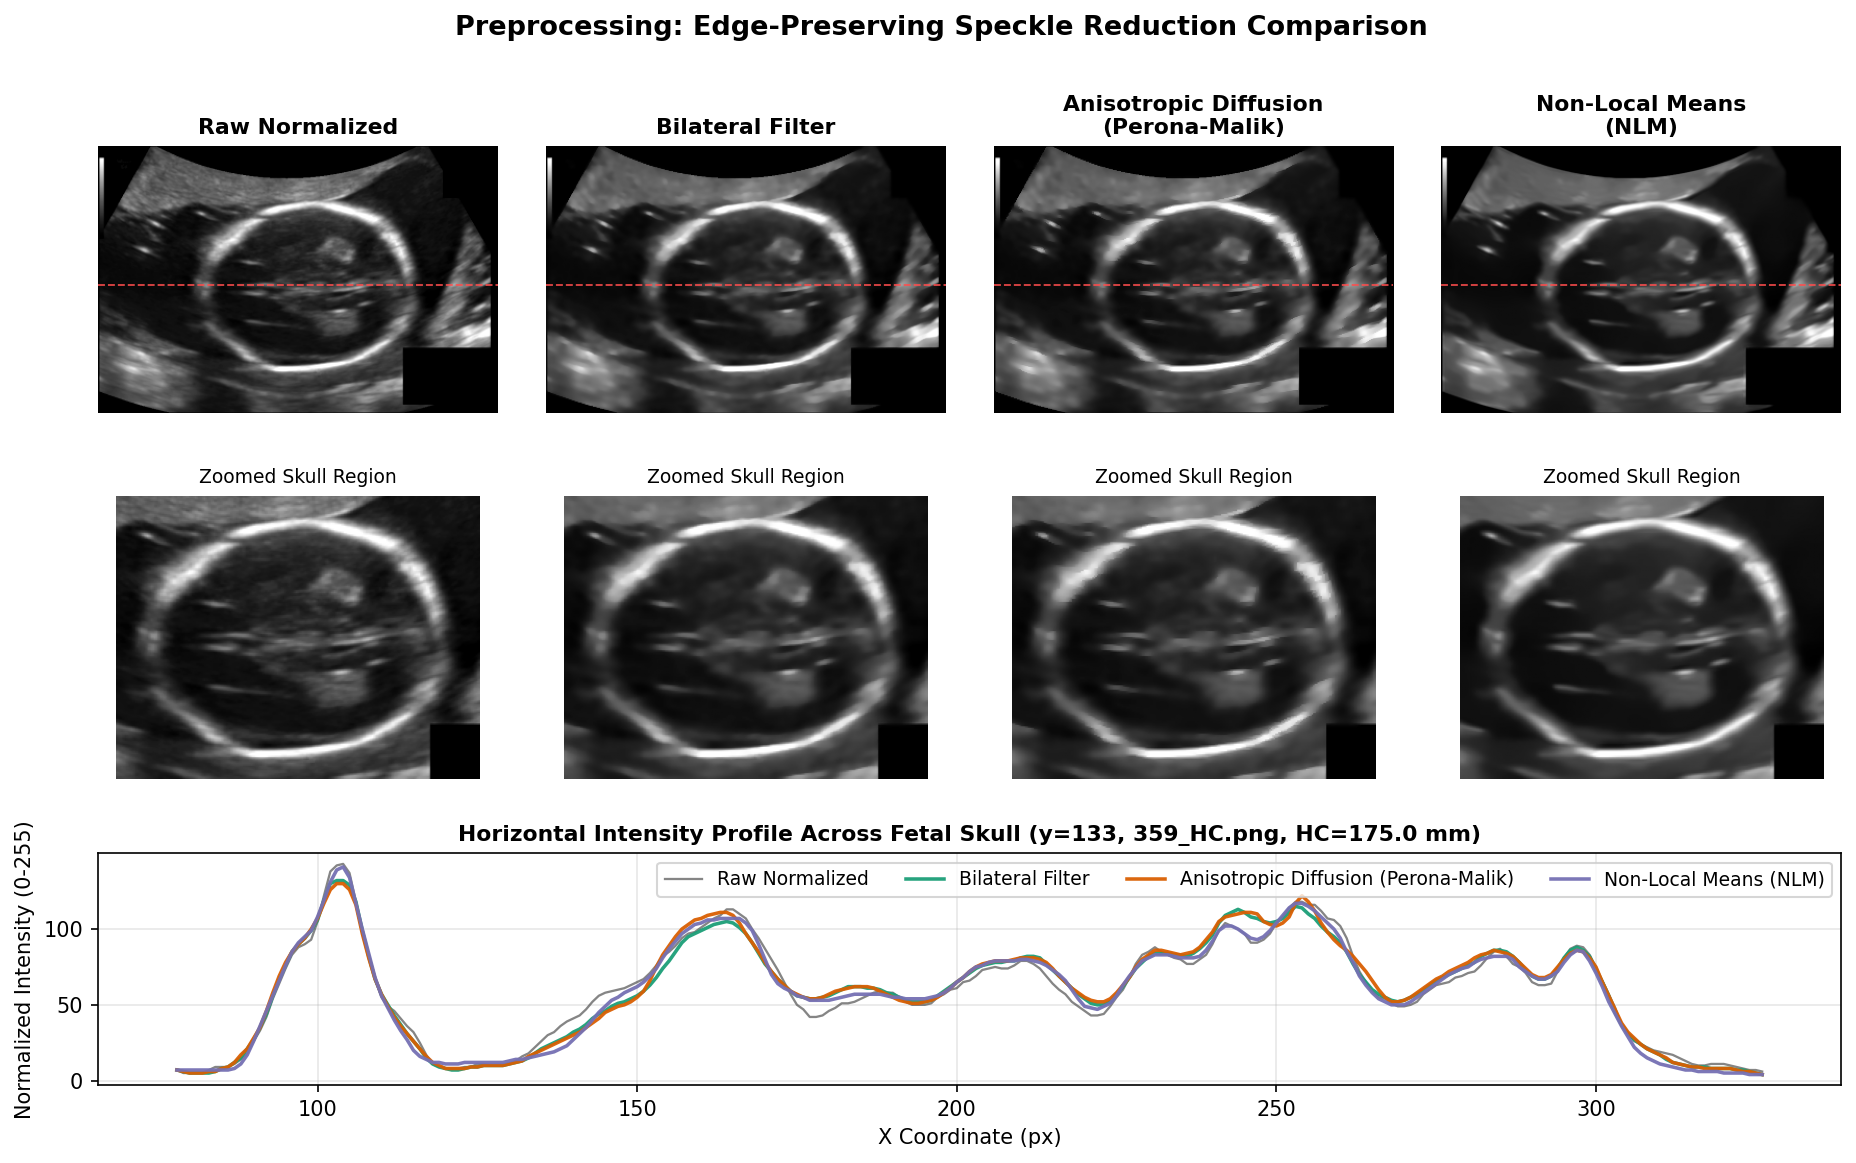

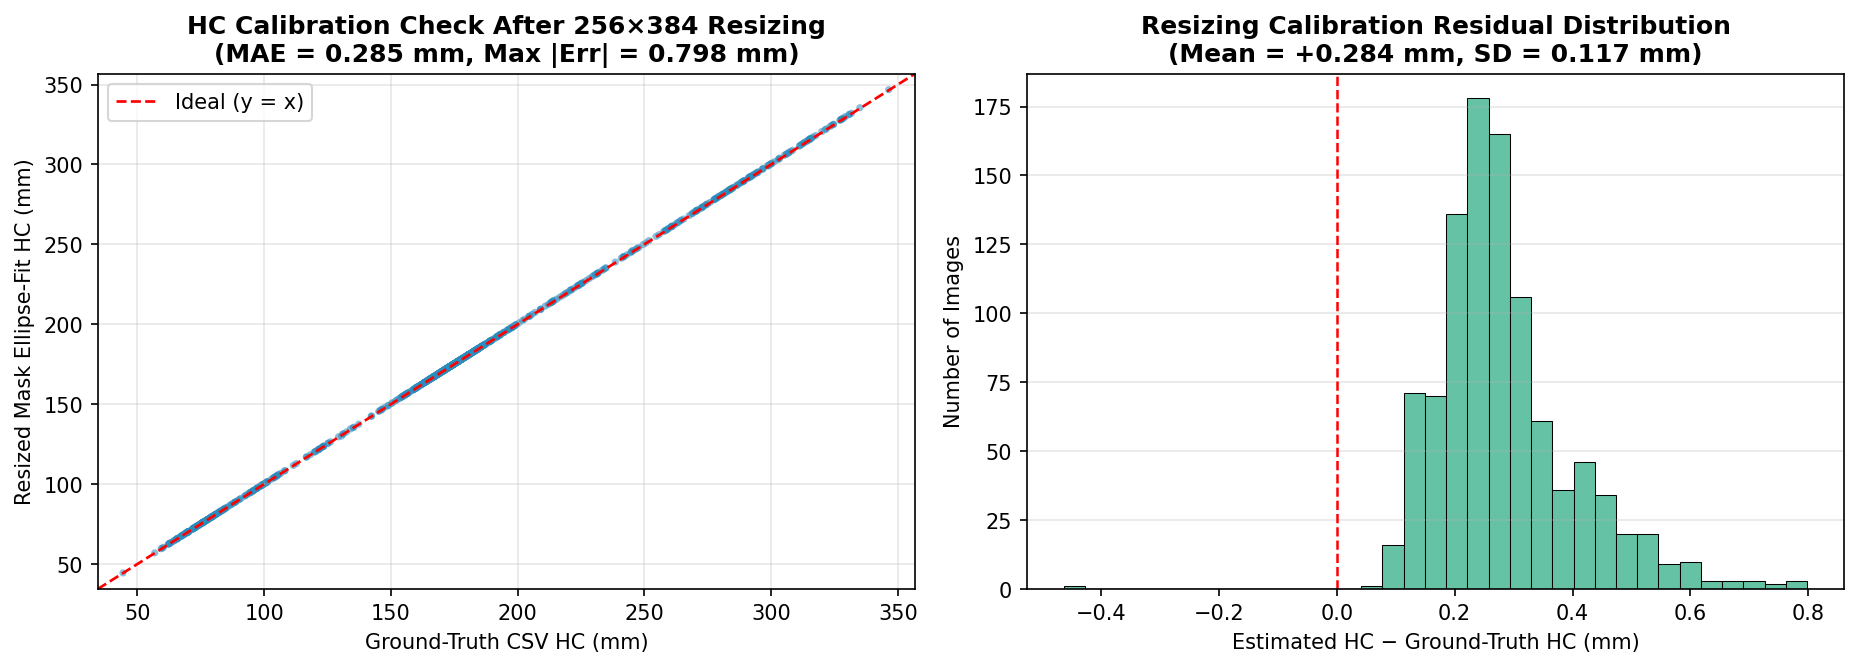

In [5]:
from src.preprocessing.run_preprocessing import (
    run_preprocessing_pipeline,
    plot_filter_comparison,
    plot_calibration_check,
)

processed_df, filter_bench_df = run_preprocessing_pipeline(
    despeckle_method="anisotropic_diffusion",
    norm_method="robust_minmax",
    target_size=DEFAULT_TARGET_SIZE,
)

print(f"Processed {len(processed_df)} image/mask pairs -> {PROCESSED_DATA_DIR}")
print(
    f"HC calibration check after resizing: MAE = {processed_df['resize_hc_abs_err_mm'].mean():.3f} mm | "
    f"Median |Err| = {processed_df['resize_hc_abs_err_mm'].median():.3f} mm | "
    f"95th pct = {processed_df['resize_hc_abs_err_mm'].quantile(0.95):.3f} mm"
)

print("\nValidation-set edge-preserving filter benchmark (n=148):")
display(filter_bench_df)

filter_fig = plot_filter_comparison(processed_df)
cal_fig = plot_calibration_check(processed_df)
display(Image(filename=str(filter_fig)))
display(Image(filename=str(cal_fig)))